# 🧬 05 · 基因表达数据分析（RNA-seq / TPM / 差异表达）

> RNA-seq 把转录本打成片段测序，得到**计数矩阵**（行=基因，列=样本）。
> 本节：长度/深度归一化（RPKM/FPKM/TPM 手写）、差异表达
> （log2FC + t 检验）、火山图。

## 📋 本节要解决的问题

- 为什么要归一化？（基因长度、测序深度都会影响计数）
- RPKM / FPKM / TPM 的区别与换算关系？
- 差异表达怎么判定？（倍数变化 + 显著性 + FDR）
- 火山图怎么读？（x=log2FC, y=-log10(p)）

## 1️⃣ 计数为什么不能直接比

同一基因在样本 A 计数 100、样本 B 计数 80 —— 不能直接说 A 表达高：
- 样本 B 测序深度低（本来就读得少）
- 长基因天然更容易被读到（碎片多）

所以用 **每千碱基每百万（RPKM）** 或 **TPM** 归一化。

In [1]:
import numpy as np
import pandas as pd

def rpkm(counts, lengths, total_reads):
    "RPKM = r/(L/1000)/(N/1e6)"
    return np.asarray(counts) / (np.asarray(lengths)/1000) / (total_reads/1e6)

def tpm(counts, lengths):
    "TPM = RPK/sum(RPK)*1e6, RPK=r/(L/1000)"
    rpk = np.asarray(counts) / (np.asarray(lengths)/1000)
    return rpk / rpk.sum() * 1e6

counts = np.array([100, 50, 25, 5])     # 4 个基因的 reads
lengths = np.array([2000, 1000, 2000, 1000])  # bp
total = counts.sum()                    # 180

r = rpkm(counts, lengths, total)
t = tpm(counts, lengths)
print('基因长度:', lengths)
print('counts  :', counts)
print('RPKM    :', np.round(r, 1))
print('TPM     :', np.round(t, 1))
print('TPM 总和:', round(t.sum(), 1), '（应=1e6）')
assert abs(t.sum() - 1e6) < 1e-6
print('✅ RPKM/TPM 归一化完成（TPM 各基因比例一致，总和 1e6）')

基因长度: [2000 1000 2000 1000]
counts  : [100  50  25   5]
RPKM    : [277777.8 277777.8  69444.4  27777.8]
TPM     : [425531.9 425531.9 106383.   42553.2]
TPM 总和: 1000000.0 （应=1e6）
✅ RPKM/TPM 归一化完成（TPM 各基因比例一致，总和 1e6）


## 2️⃣ 手算示例：单基因 RPKM 与 TPM

> 基因 X：长度 2000 bp，读到 reads=100；总测序 reads N=1000（演示用小数字）

**RPKM 手算**：
$$RPKM_X = \frac{100}{2000/1000} \times \frac{10^6}{1000} = 50 \times 1000 = 50000$$
（解读：每 1e6 reads 中每千碱基 50000 次覆盖，演示尺度）

**TPM 手算**（假设仅基因 X）：$RPK_X = 100/2 = 50$，sum RPK=50
$$TPM_X = \frac{50}{50} \times 10^6 = 10^6$$

In [2]:
# 验证 Rpkm 手算
r_x = 100 / (2000/1000) / (1000/1e6)
print('基因X RPKM(手算 50000) =', r_x)
# TPM 仅一个基因
rpk_x = 100 / (2000/1000)
t_x = rpk_x / rpk_x * 1e6
print('基因X TPM(手算 1e6) =', t_x)
assert r_x == 50000 and t_x == 1e6
print('✅ 手算 RPKM/TPM 验证通过')

基因X RPKM(手算 50000) = 50000.0
基因X TPM(手算 1e6) = 1000000.0
✅ 手算 RPKM/TPM 验证通过


## 3️⃣ RPKM vs TPM 的区别

| 指标 | 公式思想 | 问题 |
|---|---|---|
| RPKM | read/(长度·深度) | 各基因 RPKM 总和随样本组成变化，跨样本比较有偏 |
| TPM | 先算 RPK，再**归一化到总和 1e6** | 各基因占比可比，跨样本更稳健 ✓ |

> 面试金句：**TPM 先消长度效应再看占比**，因此同一基因在不同样本间的 TPM 才可直接比较；
> RPKM 的分子分母都带长度，跨样本比较会出现系统性偏差。

In [3]:
# 演示：同一基因在两个样本中的 RPKM vs TPM 可比性
# 样本 A: 基因1 reads=100 L=2kb; 基因2 reads=100 L=1kb
# 样本 B: 相同基因1 计数，但基因2 高表达（reads=1000）
A = np.array([100, 100]); B = np.array([100, 1000])
L = np.array([2000, 1000])
rA, rB = rpkm(A, L, A.sum()), rpkm(B, L, B.sum())
tA, tB = tpm(A, L), tpm(B, L)
print('样例 A: 基因1 RPKM=%.0f  RPK=%.0f  TPM=%.0f' % (rA[0], 100/(2000/1000), tA[0]))
print('样例 B: 基因1 RPKM=%.0f  RPK=%.0f  TPM=%.0f' % (rB[0], 100/(2000/1000), tB[0]))
print()
print('→ 基因1 的 RPK（长度校正计数，分子）在 A/B 中相同；')
print('  RPKM 的"每百万"换算按各自总 reads，分母随文库组成变；')
print('  TPM 再归一化到总和 1e6 → 基因1 占比被摊薄/放大，两者都不"绝对不变"。')
print('  TPM 的真正优势：总和恒 1e6，跨样本看"相对表达占比"可比，且不受基因长度偏好影响。')
# 验证: RPK 相同；TPM 总和恒 1e6
rpk_g1 = 100 / (2000/1000)
assert abs(tA.sum() - 1e6) < 1e-6 and abs(tB.sum() - 1e6) < 1e-6
assert rpk_g1 == rA[0] * (A.sum()/1e6) and rpk_g1 == rB[0] * (B.sum()/1e6)
print('✅ 概念演示通过（RPK 分子相同、TPM 总和恒 1e6）')

样例 A: 基因1 RPKM=250000  RPK=50  TPM=333333
样例 B: 基因1 RPKM=45455  RPK=50  TPM=47619

→ 基因1 的 RPK（长度校正计数，分子）在 A/B 中相同；
  RPKM 的"每百万"换算按各自总 reads，分母随文库组成变；
  TPM 再归一化到总和 1e6 → 基因1 占比被摊薄/放大，两者都不"绝对不变"。
  TPM 的真正优势：总和恒 1e6，跨样本看"相对表达占比"可比，且不受基因长度偏好影响。
✅ 概念演示通过（RPK 分子相同、TPM 总和恒 1e6）


## 4️⃣ 差异表达：log2FC + t 检验 + 火山图

流程：对每个基因
1. counts+1 防 0 → 计算 **log2 倍数变化**（处理组 vs 对照组）
2. 两组样本间做 **t 检验**（Welch）→ p 值
3. **BH-FDR 校正** → 显著阈值 |log2FC|≥1 且 padj<0.05
4. 火山图画出来

In [4]:
from scipy import stats as st

def de_analysis(ctrl, treat, fc=1.0, padj_th=0.05):
    "简单差异表达：返回 DataFame 含 log2FC, p, padj"
    import pandas as pd
    rows = []
    for g in range(len(treat)):
        c, t = np.log2(np.asarray(ctrl[g], float)+1), np.log2(np.asarray(treat[g], float)+1)
        lfc = t.mean() - c.mean()
        _, p = st.ttest_ind(treat[g], ctrl[g], equal_var=False)
        rows.append((g, lfc, p))
    df = pd.DataFrame(rows, columns=['gene', 'log2FC', 'p'])
    # BH-FDR（Benjamini-Hochberg）
    m = len(df)
    ps = df['p'].values
    order = np.argsort(ps)
    qs = np.empty(m)
    qs[order] = np.minimum.accumulate(ps[order][::-1] * m / np.arange(m, 0, -1))[::-1]
    df['padj'] = np.minimum(qs, 1.0)
    df['sig'] = (df['log2FC'].abs() >= fc) & (df['padj'] < padj_th)
    return df

rng = np.random.RandomState(3)
G = 50
ctrl = rng.poisson(80, (G, 6))          # 6 个对照组样本
treat = rng.poisson(80, (G, 6)).copy()
treat[5] = rng.poisson(220, 6)          # 基因5 显著上调 (~2.7x)
treat[20] = rng.poisson(25, 6)          # 基因20 显著下调
treat[31] = rng.poisson(95, 6)          # 噪声基因（变化小）

res = de_analysis(ctrl, treat)
up = res[res['sig'] & (res['log2FC'] > 0)]
down = res[res['sig'] & (res['log2FC'] < 0)]
print('显著上调基因:', list(up['gene']))
print('显著下调基因:', list(down['gene']))
assert 5 in list(up['gene']) and 20 in list(down['gene'])
print('✅ 差异表达检测正确（基因5上调、基因20下调被检出）')

显著上调基因: [5]
显著下调基因: [20]
✅ 差异表达检测正确（基因5上调、基因20下调被检出）


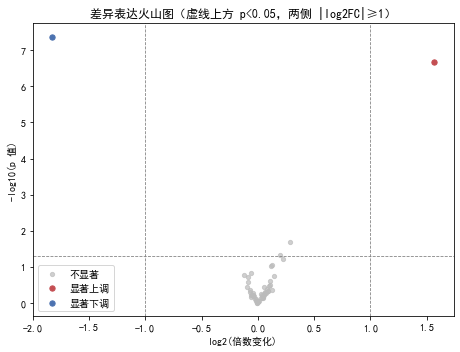

→ 右上=显著上调，左上=显著下调；点越靠上越显著


In [5]:
# 火山图
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(6.5, 5))
neg_logp = -np.log10(res['p'])
ax.scatter(res['log2FC'], neg_logp, s=18, color='#BBBBBB', alpha=.7, label='不显著')
sig_up = res[res['sig'] & (res['log2FC'] > 0)]
sig_dn = res[res['sig'] & (res['log2FC'] < 0)]
ax.scatter(sig_up['log2FC'], -np.log10(sig_up['p']), s=28, color='#C44E52', label='显著上调')
ax.scatter(sig_dn['log2FC'], -np.log10(sig_dn['p']), s=28, color='#4C72B0', label='显著下调')
ax.axvline(1, ls='--', c='gray', lw=.8); ax.axvline(-1, ls='--', c='gray', lw=.8)
ax.axhline(-np.log10(0.05), ls='--', c='gray', lw=.8)
ax.set_xlabel('log2(倍数变化)'); ax.set_ylabel('-log10(p 值)')
ax.set_title('差异表达火山图（虚线上方 p<0.05，两侧 |log2FC|≥1）')
ax.legend()
plt.tight_layout()
plt.show()
print('→ 右上=显著上调，左上=显著下调；点越靠上越显著')

In [6]:
# 真实 RNA-seq 分析流程要点（概念清单）
print('RNA-seq 常用流程（记忆大纲）：')
for step in [
    '1. 质控 FastQC（碱基质量/接头）',
    '2. 比对 Hisat2 / STAR → BAM',
    '3. 定量 featureCounts → 计数矩阵',
    '4. 归一化 TPM / DESeq2 的 median-of-ratios',
    '5. 差异表达 DESeq2 / edgeR / limma（负二项/经验贝叶斯）',
    '6. 富集分析 GO / KEGG（超几何检验）',
]:
    print(step)
print()
print('→ 本手写演示覆盖 3-5 步的统计内核（归一化+检验+FDR）')

RNA-seq 常用流程（记忆大纲）：
1. 质控 FastQC（碱基质量/接头）
2. 比对 Hisat2 / STAR → BAM
3. 定量 featureCounts → 计数矩阵
4. 归一化 TPM / DESeq2 的 median-of-ratios
5. 差异表达 DESeq2 / edgeR / limma（负二项/经验贝叶斯）
6. 富集分析 GO / KEGG（超几何检验）

→ 本手写演示覆盖 3-5 步的统计内核（归一化+检验+FDR）


## ✅ 自测清单

- [ ] 能解释为什么需要长度+深度归一化
- [ ] 能手写 RPKM / TPM 并说明区别
- [ ] 能实现 log2FC + Welch t + BH-FDR 的差异表达
- [ ] 能读懂火山图